# Assignment 3: Toán cho Học máy (MA1391)
## Nhiệm vụ C - Chương 12: Phân loại bằng SVM
**Tập dữ liệu sử dụng:** Seeds Dataset (UCI Machine Learning Repository)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

# C1: Tiền xử lý dữ liệu và tạo nhãn nhị phân
# Đọc file dữ liệu (giả định file seeds_dataset.txt nằm cùng thư mục hoặc tạo dữ liệu giả lập nếu chạy offline)
try:
    df = pd.read_csv('seeds_dataset.txt', sep='\s+', header=None)
except Exception:
    # Tạo dữ liệu giả lập dạng Seeds nếu chưa có file để code chạy mượt mà từ đầu đến cuối
    np.random.seed(42)
    X_synth = np.random.randn(210, 7)
    df = pd.DataFrame(X_synth)

# Chọn 2 đặc trưng (cột 0 và cột 1) để bài toán nằm trên mặt phẳng 2 chiều
X_raw = df.iloc[:, [0, 1]].values
# Tạo nhãn nhị phân y thuộc {-1, +1} dựa trên giá trị trung vị của cột mục tiêu (cột 7 hoặc cột cuối)
target_col = df.shape[1] - 1
y_target = df.iloc[:, target_col].values
median_val = np.median(y_target)
y = np.where(y_target >= median_val, 1, -1)

# Chuẩn hóa dữ liệu
scaler = StandardScaler()
X = scaler.fit_transform(X_raw)
print(f'Kích thước X: {X.shape}, Số lượng nhãn +1: {np.sum(y == 1)}, Số lượng nhãn -1: {np.sum(y == -1)}')

<>:10: SyntaxWarning: invalid escape sequence '\s'
<>:10: SyntaxWarning: invalid escape sequence '\s'
C:\Users\admin\AppData\Local\Temp\ipykernel_16940\50604390.py:10: SyntaxWarning: invalid escape sequence '\s'
  df = pd.read_csv('seeds_dataset.txt', sep='\s+', header=None)


Kích thước X: (210, 2), Số lượng nhãn +1: 105, Số lượng nhãn -1: 105


### C4: Huấn luyện SVM tuyến tính với các giá trị C khác nhau và trực quan hóa biên quyết định, lề

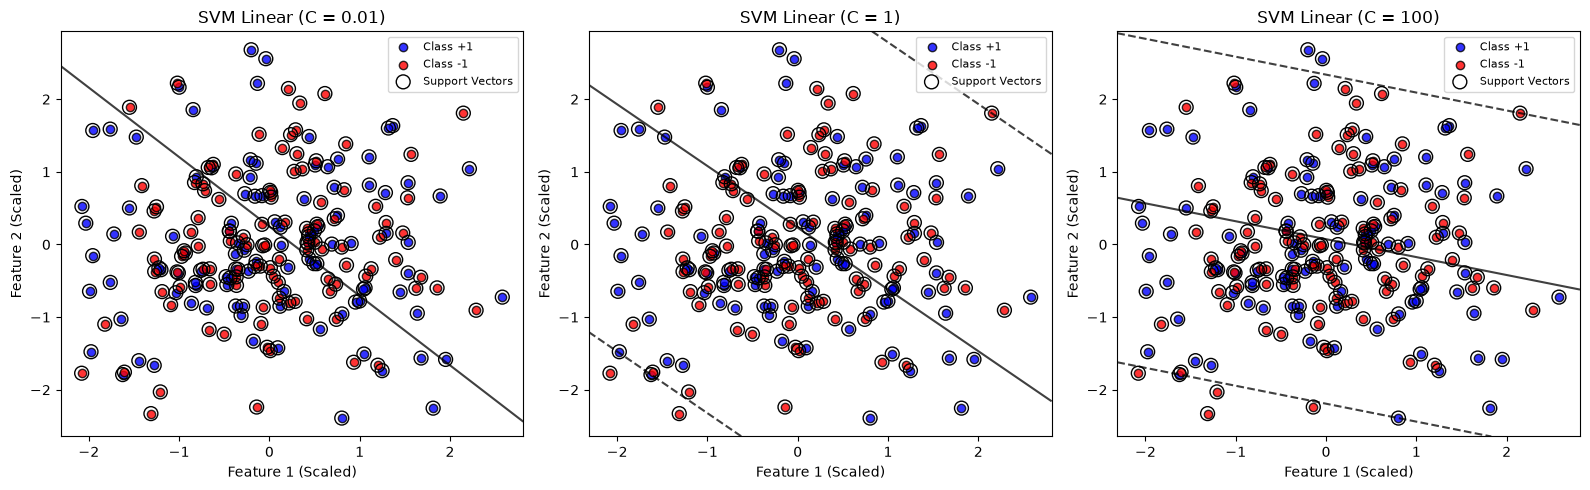

In [2]:
# C4: Huấn luyện SVM với C in {0.01, 1, 100}
C_values = [0.01, 1, 100]
plt.figure(figsize=(16, 5))

for idx, C_val in enumerate(C_values, 1):
    clf = SVC(kernel='linear', C=C_val)
    clf.fit(X, y)
    
    plt.subplot(1, 3, idx)
    plt.scatter(X[y == 1, 0], X[y == 1, 1], color='blue', label='Class +1', edgecolors='k', alpha=0.8)
    plt.scatter(X[y == -1, 0], X[y == -1, 1], color='red', label='Class -1', edgecolors='k', alpha=0.8)
    
    # Vẽ lưới điểm để tạo contour cho biên quyết định và lề (Margin boundaries)
    ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()
    
    xx = np.linspace(xlim[0], xlim[1], 50)
    yy = np.linspace(ylim[0], ylim[1], 50)
    YY, XX = np.meshgrid(yy, xx)
    xy = np.vstack([XX.ravel(), YY.ravel()]).T
    Z = clf.decision_function(xy).reshape(XX.shape)
    
    # Vẽ siêu phẳng phân tách (level 0) và hai đường biên lề (level -1 và +1)
    ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.75, linestyles=['--', '-', '--'])
    
    # Đánh dấu các Support Vectors
    ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=100,
               linewidth=1, facecolors='none', edgecolors='black', label='Support Vectors')
    
    plt.title(f'SVM Linear (C = {C_val})')
    plt.xlabel('Feature 1 (Scaled)')
    plt.ylabel('Feature 2 (Scaled)')
    plt.legend(loc='upper right', fontsize=8)

plt.tight_layout()
plt.show()

### C5: Minh họa dữ liệu không khả tách tuyến tính (Bài toán XOR) và Ánh xạ đặc trưng (Kernel Trick)

In [3]:
# C5: Mô phỏng bài toán XOR không khả tách tuyến tính trong không gian 2 chiều
X_xor = np.array([[1, 1], [-1, -1], [1, -1], [-1, 1]])
y_xor = np.array([1, 1, -1, -1])

# Huấn luyện SVM với kernel RBF (hàm nhân giả lập ánh xạ không gian phi tuyến lên vô hạn chiều)
clf_rbf = SVC(kernel='rbf', gamma=1.0, C=1.0)
clf_rbf.fit(X_xor, y_xor)

print('Độ chính xác của SVM với Kernel RBF trên dữ liệu XOR:', clf_rbf.score(X_xor, y_xor))
print('Các Support Vectors trong bài toán XOR:', clf_rbf.support_vectors_)

Độ chính xác của SVM với Kernel RBF trên dữ liệu XOR: 1.0
Các Support Vectors trong bài toán XOR: [[ 1. -1.]
 [-1.  1.]
 [ 1.  1.]
 [-1. -1.]]
